In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import charge_trap_pot_model as ctm 
import time


np.set_printoptions(threshold=sys.maxsize)

In [2]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20        # meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)

ModCT = ctm.Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, t_ox=7, t_sige=48)


lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418


In [ ]:
XCT = (NSC+NSM/2)*AX

# Define the boundary points
a = -100*AY
b = 0
c = M*AY
d = (M+100)*AY

# Define the number of points between each segment
n_ab = 50  # number of points between a and b
n_bc = 101  # number of points between b and c (more points)
n_cd = 50  # number of points between c and d

#n_ab = 5  # number of points between a and b
#n_bc = 11  # number of points between b and c (more points)
#n_cd = 5  # number of points between c and d


# Create linearly spaced points between each pair
y_ab = np.linspace(a, b, n_ab, endpoint=False)
y_bc = np.linspace(b, c, n_bc, endpoint=False)
y_cd = np.linspace(c, d, n_cd, endpoint=True)

# Concatenate all points
YCT = np.concatenate((y_ab, y_bc, y_cd))

#print(YCT)

#YCT = np.linspace(-200*AY,(M+200)*AY,101)

ZCT = 7
ZIM = 0   ### immaterial in img charge model 
ZQW = 57

print('X co-ordinate of charge trap =', XCT )

Ep = np.empty((YCT.shape[0],K_NUM))

for i in range(YCT.shape[0]):

    H = ModCT.H_sys(PHI, 'li', XCT, YCT[i], ZCT, ZIM, ZQW, f_ct=1)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)

    Ep[i,:] = Es

    if i%1==0:
        print(Ep[i,:])

#np.save('linear_E_vs_yct_image_chrg_model_full.npy', Ep)

X co-ordinate of charge trap = 4150.0
[-0.16647358 -0.1664577  -0.07709674 -0.07692385  0.07692385  0.07709674
  0.1664577   0.16647358]
[-0.16647354 -0.16645766 -0.07709648 -0.0769236   0.0769236   0.07709648
  0.16645766  0.16647354]
[-0.16647351 -0.16645762 -0.07709621 -0.07692333  0.07692333  0.07709621
  0.16645762  0.16647351]
[-0.16647346 -0.16645758 -0.07709592 -0.07692305  0.07692305  0.07709592
  0.16645758  0.16647346]
[-0.16647342 -0.16645754 -0.07709561 -0.07692274  0.07692274  0.07709561
  0.16645754  0.16647342]
[-0.16647337 -0.16645749 -0.07709528 -0.07692242  0.07692242  0.07709528
  0.16645749  0.16647337]
[-0.16647333 -0.16645744 -0.07709493 -0.07692207  0.07692207  0.07709493
  0.16645744  0.16647333]
[-0.16647327 -0.16645738 -0.07709456 -0.0769217   0.0769217   0.07709456
  0.16645738  0.16647327]
[-0.16647322 -0.16645733 -0.07709416 -0.07692131  0.07692131  0.07709416
  0.16645733  0.16647322]
[-0.16647316 -0.16645727 -0.07709373 -0.07692089  0.07692089  0.0770937

In [8]:
#Ep_cu_mm2d = np.load('cubic_E_vs_yct_Zdiff_14_wider_yct_width_75nm_refined.npy')
Ep_li_ctm = np.load('linear_E_vs_yct_image_chrg_model_full.npy')

Text(0, 0.5, '$\\dfrac{E_s}{E_{s0}}$')

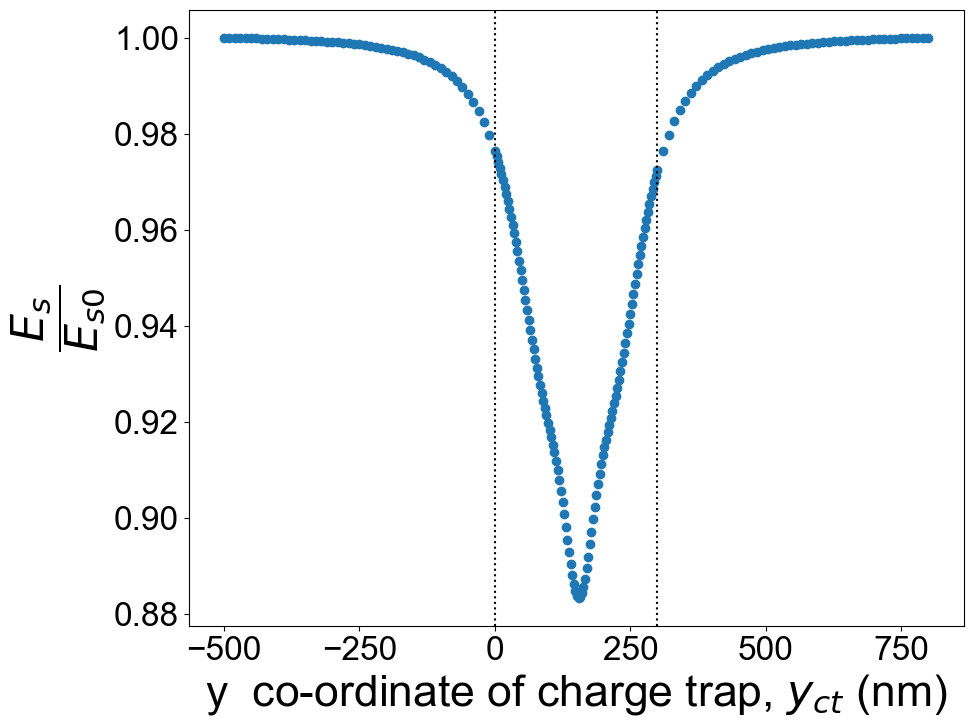

In [9]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

ax = plt.axis()

linear_spin_split = Ep_li_ctm[:, K_NUM//2+1]-Ep_li_ctm[:, K_NUM//2] 

min_spin_split = np.min(linear_spin_split)

max_spin_split = np.max(linear_spin_split)

Ep_wct = (Ep_li_ctm[:, K_NUM//2+1]-Ep_li_ctm[:, K_NUM//2])/max_spin_split


plt.scatter(YCT, Ep_wct )
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')

plt.xlabel(r'y  co-ordinate of charge trap, $y_{ct}$ (nm)', fontsize=32)
plt.ylabel(r'$\dfrac{E_s}{E_{s0}}$', fontsize=32)

#plt.ylim(ymin=0)